# Meta-modelo: combinación del XGBoost y la red

El XGBoost (modelo A) y la CNN-Transformer (modelo B) ven la noche de forma distinta: A mira 100 rasgos calculados de cada época (las columnas más importantes de los 719) y B aprende de la señal cruda de 80 épocas seguidas. Los dos se equivocan, pero no siempre en las mismas épocas. El objetivo de este notebook es entrenar un **meta-modelo** que recibe las probabilidades de los dos y aprende a quién creerle en cada caso. Como A y B, es **uno solo para las 12 combinaciones de canales**.

La entrada son las predicciones fuera de fold y de test que dejaron `modelo_a_xgboost_100_features/1_entrenamiento.ipynb` y `modelo_b_red/2_entrenamiento.ipynb`. El meta-modelo queda en `modelo/meta_modelo/`, y `modelo/sistema.json` describe cómo se combinan las tres piezas.

El notebook se organiza así:

1. **Librerías**
2. **Rutas y parámetros**
3. **Predicciones de A y B:** lectura, alineación y votación simple.
4. **¿Se equivocan en lo mismo?**
5. **Entradas del meta-modelo**
6. **Entrenamiento:** validación cruzada y modelo final.
7. **Resultados:** CV, test, diferencias con IC, F1 por estadio y matrices de confusión.
8. **Usar el modelo guardado**
9. **Conclusiones**

## 1. Librerías

In [1]:
import json
import warnings
from pathlib import Path

import joblib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import xgboost as xgb
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, cohen_kappa_score, confusion_matrix, f1_score
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.utils.class_weight import compute_sample_weight

warnings.filterwarnings("ignore")
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False})

## 2. Rutas y parámetros

A es el XGBoost de 100 columnas de `modelo_a_xgboost_100_features/1_entrenamiento.ipynb` (`modelo/modelo_a_xgboost_100_features/`). Sus predicciones están en `data/procesados/modelo_a_xgboost_100_features/folds/` y las de B en `data/procesados/modelo_b_red/predicciones/`: un archivo por fold y uno del modelo final (`final.npz`), que predice el test.

In [2]:
# Raíz del repositorio: la carpeta que tiene particiones.json
RAIZ = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "particiones.json").exists())
MODELO_A = "modelo_a_xgboost_100_features"   # carpeta del XGBoost en modelo/
PRED_A = RAIZ / "data" / "procesados" / MODELO_A / "folds"
PRED_B = RAIZ / "data" / "procesados" / "modelo_b_red" / "predicciones"
PROCESADOS = RAIZ / "data" / "procesados" / "meta_modelo"
MODELO = RAIZ / "modelo" / "meta_modelo"

SEED = 42
N_BOOT = 2000
ESTADIOS = ["W", "N1", "N2", "N3", "REM"]
K = len(ESTADIOS)
MODALIDADES = ("fpz", "pz", "eog", "emg")

particion = json.loads((RAIZ / "particiones.json").read_text())
CONFIGS = {k: tuple(v) for k, v in particion["combinaciones"].items()}


def mascara(cfg):
    """[fpz, pz, eog, emg] -> True si el canal está en la combinación."""
    return [m in CONFIGS[cfg] for m in MODALIDADES]

## 3. Predicciones de A y B

### Modelo A

Leemos las predicciones del XGBoost: las de los 5 folds juntas dan las **fuera de fold** de los 62 sujetos de desarrollo (CV), y las del modelo final, las del test.

In [3]:
# Función para leer las predicciones del XGBoost
def load_a(name):
    """combinación -> noche -> (y, probabilidades)"""
    z = np.load(PRED_A / f"{name}.npz")
    out = {}
    for k in z.files:
        cfg, n, kind = k.split("__")
        if kind == "y":
            out.setdefault(cfg, {})[n] = (z[k], z[f"{cfg}__{n}__pred"])
    return out


FOLDS = [f"fold_{f['fold']}" for f in particion["folds"]]
A = {c: {"oof": {}, "test": {}} for c in CONFIGS}
for name in FOLDS + ["final"]:
    for c, d in load_a(name).items():
        A[c]["test" if name == "final" else "oof"].update(d)
print(f"A: {len(A['fpz']['oof'])} noches de CV y {len(A['fpz']['test'])} de test, con 12 combinaciones")

A: 121 noches de CV y 32 de test, con 12 combinaciones


### Modelo B y alineación

Las dos predicciones vienen por noche, pero no cubren exactamente las mismas épocas:
- A predice toda la ventana de sueño, incluidas las épocas sin etiqueta (y = −1);
- B solo predice las épocas con etiqueta.

Para que el meta-modelo pueda mirar las épocas vecinas sin huecos, las predicciones de B se ubican en la ventana de A, y las épocas sin etiqueta toman la probabilidad de la época anterior.

In [4]:
# Función para ubicar las predicciones de B en la ventana de A
def fill_window(y_window, y_valid, p_valid):
    valid = y_window >= 0
    assert np.array_equal(y_window[valid], y_valid), "las etiquetas de A y B no coinciden"
    idx = np.where(valid, np.arange(len(y_window)), -1)
    idx = np.maximum.accumulate(idx)
    idx[idx < 0] = np.argmax(valid)
    full = np.empty((len(y_window), p_valid.shape[1]), dtype=np.float32)
    full[valid] = p_valid
    full[~valid] = full[idx[~valid]]
    return full

In [5]:
# Lectura de las predicciones de B, ya alineadas con A
def load_b(name, key):
    z = np.load(PRED_B / f"{name}.npz")
    out = {c: {} for c in CONFIGS}
    for k in z.files:
        cfg, n = k.split("__")
        if cfg in CONFIGS:
            yw = A[cfg][key][n][0]
            out[cfg][n] = (yw, fill_window(yw, z[f"y__{n}"], z[k]))
    return out


B = {c: {"oof": {}, "test": {}} for c in CONFIGS}
for name in FOLDS + ["final"]:
    key = "test" if name == "final" else "oof"
    for c, d in load_b(name, key).items():
        B[c][key].update(d)
for c in CONFIGS:
    for key in ("oof", "test"):
        assert sorted(B[c][key]) == sorted(A[c][key]), f"{c}: A y B no tienen las mismas noches"

sin_etiqueta = sum((y < 0).sum() for y, _ in A["fpz"]["oof"].values()) + sum((y < 0).sum() for y, _ in A["fpz"]["test"].values())
print(f"B alineado con A · {sin_etiqueta} épocas sin etiqueta en las 153 noches")

B alineado con A · 298 épocas sin etiqueta en las 153 noches


### Votación simple

La **votación** es el promedio de las probabilidades de A y B, sin aprender nada. Sirve de referencia: el meta-modelo solo vale la pena si hace algo más que juntar los dos modelos.

In [6]:
# Votación: promedio de A y B
VOT = {c: {key: {n: (y, (p + B[c][key][n][1]) / 2) for n, (y, p) in A[c][key].items()} for key in ("oof", "test")}
       for c in CONFIGS}

## 4. ¿Se equivocan en lo mismo?

Si A y B fallaran en las mismas épocas, combinarlos no serviría de nada. La regla del proyecto: el segundo modelo vale la pena si comparte **menos del 70 %** de los errores del primero, en la CV.

In [7]:
# Errores de A, de B y de los dos a la vez, en la CV
filas = []
for c in CONFIGS:
    a, b = A[c]["oof"], B[c]["oof"]
    ns = sorted(a)
    y = np.concatenate([a[n][0] for n in ns])
    v = y >= 0
    y = y[v]
    pa = np.concatenate([a[n][1].argmax(1) for n in ns])[v]
    pb = np.concatenate([b[n][1].argmax(1) for n in ns])[v]
    ea, eb = pa != y, pb != y
    filas.append({"combinación": c, "error A": ea.mean(), "error B": eb.mean(), "fallan los dos": (ea & eb).mean(),
                  "errores de A que B también comete": (ea & eb).sum() / ea.sum(),
                  "N1: B acierta donde A falla": (ea & ~eb & (y == 1)).sum() / (ea & (y == 1)).sum()})
pd.DataFrame(filas).set_index("combinación").style.format("{:.1%}")

,error A,error B,fallan los dos,errores de A que B también comete,N1: B acierta donde A falla
combinación,,,,,
fpz,18.7%,18.0%,10.6%,56.8%,41.1%
pz,21.2%,19.9%,12.9%,61.1%,37.2%
eeg2,17.0%,16.3%,10.1%,59.3%,37.7%
fpz_eog,17.9%,17.1%,10.1%,56.3%,43.0%
pz_eog,19.5%,17.5%,11.5%,59.0%,40.7%
eeg2_eog,16.5%,15.8%,9.8%,59.6%,37.5%
fpz_emg,18.1%,17.6%,10.4%,57.6%,38.7%
pz_emg,20.5%,19.8%,12.7%,62.3%,34.7%
eeg2_emg,16.7%,16.3%,10.1%,60.5%,35.3%


## 5. Entradas del meta-modelo

Para cada época *t* el meta-modelo recibe **54 números**:
- las **log-probabilidades** de A y de B en las épocas t−2, t−1, t, t+1 y t+2: 2 modelos × 5 épocas × 5 clases = 50. En los bordes de la noche, las vecinas que no existen valen log(1/5), es decir, "no sé";
- la **máscara** de canales presentes [Fpz-Cz, Pz-Oz, EOG, EMG]: 4. Así puede creerle distinto a cada modelo según la combinación.

Se arma una fila por época y por combinación: cada época aparece 12 veces, con lo que dijeron A y B con cada combinación.

In [8]:
# Función para armar las 54 entradas de una noche
EPS = 1e-6
CONTEXT = (-2, -1, 0, 1, 2)


def entradas(pa, pb, mask):
    """pa, pb: (épocas, 5) probabilidades de A y B; mask: [fpz, pz, eog, emg]."""
    cols = {}
    for nombre, prob in (("xgb", pa), ("b", pb)):
        lp = np.log(np.clip(prob, EPS, 1))
        for o in CONTEXT:
            shifted = np.full_like(lp, np.log(1 / K))
            if o == 0:
                shifted = lp
            elif o > 0:
                shifted[:-o] = lp[o:]
            else:
                shifted[-o:] = lp[:o]
            for k in range(K):
                cols[f"{nombre}_k{k}_o{o:+d}"] = shifted[:, k]
    df = pd.DataFrame(cols).astype(np.float32)
    for m, on in zip(MODALIDADES, mask):
        df[f"mask_{m}"] = np.float32(on)
    return df

Ejemplo: las entradas de una época de N1 de la CV, solo con Fpz-Cz, pasadas de nuevo a probabilidades. Cada fila es una época vecina y cada columna, un estadio según A o según B.

In [9]:
# Ejemplo: entradas de una época de N1
n = sorted(A["fpz"]["oof"])[0]
y, pa = A["fpz"]["oof"][n]
t = int(np.where(y == 1)[0][5])
e = entradas(pa, B["fpz"]["oof"][n][1], mascara("fpz")).iloc[t]
ejemplo = pd.DataFrame({f"{nombre} {s}": [np.exp(e[f"{m}_k{k}_o{o:+d}"]) for o in CONTEXT]
                        for nombre, m in (("A", "xgb"), ("B", "b")) for k, s in enumerate(ESTADIOS)},
                       index=[f"t{o:+d}" if o else "t" for o in CONTEXT])
print(f"{n}, época {t}: real N1 · máscara {e[[f'mask_{m}' for m in MODALIDADES]].tolist()}")
ejemplo.style.format("{:.2f}")

SC4011, época 65: real N1 · máscara [1.0, 0.0, 0.0, 0.0]


,A W,A N1,A N2,A N3,A REM,B W,B N1,B N2,B N3,B REM
t-2,0.06,0.92,0.01,0.00,0.01,0.05,0.82,0.03,0.00,0.10
t-1,0.11,0.86,0.01,0.00,0.01,0.04,0.80,0.04,0.00,0.12
t,0.11,0.85,0.02,0.00,0.02,0.02,0.67,0.07,0.00,0.24
t+1,0.12,0.83,0.03,0.00,0.02,0.02,0.58,0.08,0.00,0.33
t+2,0.14,0.61,0.13,0.00,0.11,0.01,0.27,0.11,0.00,0.62


Armamos la tabla completa de la CV y la del test.

In [10]:
# Entradas de todas las combinaciones y noches
def tabla(key):
    frames = []
    for c in CONFIGS:
        for n in sorted(A[c][key]):
            y, pa = A[c][key][n]
            d = entradas(pa, B[c][key][n][1], mascara(c))
            d.insert(0, "y", y)
            d.insert(0, "night", n)
            d.insert(0, "config", c)
            frames.append(d)
    return pd.concat(frames, ignore_index=True)


oof_in, test_in = tabla("oof"), tabla("test")
feat = [c for c in oof_in.columns if c not in ("config", "night", "y")]
print(f"CV: {len(oof_in):,} filas · test: {len(test_in):,} filas · {len(feat)} entradas")

CV: 1,889,520 filas · test: 459,684 filas · 54 entradas


## 6. Entrenamiento

### Meta-modelo

Adentro hay dos modelos y se promedian sus probabilidades:
- **Regresión logística** (con estandarización, C = 1): aprende reglas lineales, como "si B dice N1 con fuerza y A duda, sube N1".
- **XGBoost pequeño** (profundidad 4, tasa 0.05, hasta 1000 rondas con early stopping de 50 sobre los sujetos de validación): aprende combinaciones no lineales.

Los dos usan pesos por clase balanceado^0.44, como A y B.

Se entrena solo con predicciones **fuera de fold**, de personas que A y B no vieron. Si se entrenara con predicciones sobre sus datos de entrenamiento, aprendería a creerles de más.

In [11]:
# Hiperparámetros del meta-modelo y pesos por clase
ALPHA = 0.44
XGB_PARAMS = dict(objective="multi:softprob", tree_method="hist", eval_metric="mlogloss", learning_rate=0.05,
                  max_depth=4, subsample=0.8, colsample_bytree=0.8, min_child_weight=10, n_jobs=-1)


def class_weights(y, alpha=ALPHA):
    return compute_sample_weight("balanced", y) ** alpha

In [12]:
# El meta-modelo: regresión logística + XGBoost, promediados
class MetaModelo:
    def fit(self, X, y, X_val, y_val):
        lr = make_pipeline(StandardScaler(), LogisticRegression(C=1.0, max_iter=3000, random_state=SEED))
        Xt, yt = pd.concat([X, X_val]), np.concatenate([y, y_val])   # la LR no necesita validación: usa todo
        lr.fit(Xt, yt, logisticregression__sample_weight=class_weights(yt))
        m = xgb.XGBClassifier(**XGB_PARAMS, n_estimators=1000, early_stopping_rounds=50, random_state=SEED)
        m.fit(X, y, sample_weight=class_weights(y), eval_set=[(X_val, y_val)],
              sample_weight_eval_set=[class_weights(y_val)], verbose=False)
        self.lr, self.xgb = lr, m
        return self

    def predict_proba(self, X):
        return np.mean([self.lr.predict_proba(X), self.xgb.predict_proba(X)], axis=0)

In [13]:
# Funciones para entrenar con unos sujetos y volver a separar las predicciones por noche
sujeto = oof_in.night.str[3:5].astype(int)
con_etiqueta = oof_in.y.values >= 0


def fit_meta(train_subj, val_subj):
    tr = con_etiqueta & sujeto.isin(train_subj).values
    va = con_etiqueta & sujeto.isin(val_subj).values
    return MetaModelo().fit(oof_in.loc[tr, feat], oof_in.y.values[tr], oof_in.loc[va, feat], oof_in.y.values[va])


def per_config(df, proba):
    """probabilidades de la tabla -> combinación -> noche -> (y, p)"""
    out = {}
    for (c, n), i in df.groupby(["config", "night"]).indices.items():
        out.setdefault(c, {})[n] = (df.y.values[i], proba[i].astype(np.float32))
    return out

### Validación cruzada (5 folds)

Con los mismos folds de A y B: en cada fold, el meta-modelo se entrena con los sujetos de entrenamiento, hace early stopping con los de validación y predice los del fold.

In [14]:
# Validación cruzada del meta-modelo
p_oof = np.zeros((len(oof_in), K), dtype=np.float32)
for f in particion["folds"]:
    m = fit_meta(f["train"], f["val"])
    r = sujeto.isin(f["test"]).values
    p_oof[r] = m.predict_proba(oof_in.loc[r, feat])
    print(f"fold {f['fold'] + 1}: XGBoost del meta con {m.xgb.best_iteration + 1} rondas")
META_OOF = per_config(oof_in, p_oof)

fold 1: XGBoost del meta con 465 rondas
fold 2: XGBoost del meta con 229 rondas
fold 3: XGBoost del meta con 206 rondas
fold 4: XGBoost del meta con 260 rondas
fold 5: XGBoost del meta con 145 rondas


### Modelo final

Se entrena con el split `final` (56 sujetos de entrenamiento y 6 de validación), predice el test y se guarda en `modelo/meta_modelo/`:
- `meta_lr.joblib`: la regresión logística con su estandarización;
- `meta_xgb.json`: el XGBoost;
- `columnas.json`: las 54 entradas, en orden.

In [15]:
# Modelo final, predicción del test y guardado
meta_final = fit_meta(particion["final"]["train"], particion["final"]["val"])
p_test = meta_final.predict_proba(test_in[feat]).astype(np.float32)
META_TEST = per_config(test_in, p_test)

MODELO.mkdir(parents=True, exist_ok=True)
joblib.dump(meta_final.lr, MODELO / "meta_lr.joblib")
meta_final.xgb.save_model(MODELO / "meta_xgb.json")
(MODELO / "columnas.json").write_text(json.dumps(feat))
print(f"modelo final: XGBoost del meta con {meta_final.xgb.best_iteration + 1} rondas · guardado en {MODELO.relative_to(RAIZ)}")

modelo final: XGBoost del meta con 294 rondas · guardado en modelo/meta_modelo


`sistema.json` dice qué archivos forman el sistema y cómo se combinan, incluida la carpeta del XGBoost con que se entrenó el meta-modelo (`carpeta_modelo_a`). Las predicciones del meta-modelo se guardan en `data/procesados/meta_modelo/`.

In [16]:
# Descripción del sistema y predicciones del meta-modelo
sistema = {
    "estadios": ESTADIOS,
    "modalidades": list(MODALIDADES),
    "carpeta_modelo_a": MODELO_A,
    "modelo_a": f"{MODELO_A}/xgb.json (entradas en {MODELO_A}/columnas.json; canales ausentes en NaN)",
    "modelo_b": "modelo_b_red/modelo_final.pt",
    "meta_modelo": "promedio de las probabilidades de meta_modelo/meta_lr.joblib y meta_modelo/meta_xgb.json",
    "entradas_meta": "meta_modelo/columnas.json: log-probabilidades de A y B en las épocas vecinas y máscara de canales",
    "contexto_meta": list(CONTEXT),
    "relleno_bordes": "log(1/5) en las épocas que no existen antes del inicio o después del final de la noche",
    "relleno_sin_etiqueta": "las épocas que B no predice toman la probabilidad de B de la época anterior",
}
(RAIZ / "modelo" / "sistema.json").write_text(json.dumps(sistema, indent=2, ensure_ascii=False) + "\n")

PROCESADOS.mkdir(parents=True, exist_ok=True)
arr = {}
for key, P in (("oof", META_OOF), ("test", META_TEST)):
    for c, d in P.items():
        for n, (y, p) in d.items():
            arr[f"{key}__{c}__{n}__y"], arr[f"{key}__{c}__{n}__pred"] = y, p
np.savez_compressed(PROCESADOS / "predicciones.npz", **arr)
print("guardado:", (RAIZ / "modelo" / "sistema.json").relative_to(RAIZ), "y", (PROCESADOS / "predicciones.npz").relative_to(RAIZ))

guardado: modelo/sistema.json y data/procesados/meta_modelo/predicciones.npz


## 7. Resultados

### Métricas

- **F1 macro (MF1):** la principal, el promedio del F1 de los 5 estadios.
- **κ de Cohen:** acuerdo con el técnico descontando el azar.
- **F1 de N1**, el estadio más difícil.

Solo se evalúan las épocas con etiqueta.

In [17]:
# Funciones para calcular las métricas
def compute_metrics(y_true, y_pred):
    f1 = f1_score(y_true, y_pred, labels=range(K), average=None, zero_division=0)
    return {"acc": accuracy_score(y_true, y_pred), "mf1": f1.mean(), "kappa": cohen_kappa_score(y_true, y_pred),
            **{f"f1_{s}": v for s, v in zip(ESTADIOS, f1)},
            "confusion": confusion_matrix(y_true, y_pred, labels=range(K))}


def metrics_of(preds):
    y = np.concatenate([y for y, _ in preds.values()])
    p = np.concatenate([p.argmax(1) for _, p in preds.values()])
    return compute_metrics(y[y >= 0], p[y >= 0])


META = {c: {"oof": META_OOF[c], "test": META_TEST[c]} for c in CONFIGS}
MODELOS = {"XGBoost (A)": A, "Red (B)": B, "Votación": VOT, "Meta-modelo": META}

### Validación cruzada

MF1 fuera de fold de los 62 sujetos de desarrollo, por combinación.

In [18]:
# MF1 de la CV por combinación
pd.DataFrame({name: {c: metrics_of(P[c]["oof"])["mf1"] for c in CONFIGS} for name, P in MODELOS.items()}).style.format(precision=3)

,XGBoost (A),Red (B),Votación,Meta-modelo
fpz,0.760,0.766,0.792,0.799
pz,0.716,0.737,0.750,0.760
eeg2,0.776,0.783,0.802,0.809
fpz_eog,0.770,0.780,0.801,0.808
pz_eog,0.742,0.770,0.780,0.788
eeg2_eog,0.783,0.790,0.809,0.817
fpz_emg,0.769,0.772,0.796,0.802
pz_emg,0.728,0.740,0.756,0.764
eeg2_emg,0.781,0.784,0.803,0.810
fpz_eog_emg,0.778,0.781,0.803,0.810


### Test

Los 16 sujetos de test, que no se usaron para ninguna decisión.

**Intervalos de confianza por bootstrap agrupado por sujeto.** Las épocas de una persona no son independientes, así que se remuestrean **personas** con reemplazo, 2000 veces (semilla 42), y se recalculan las métricas. El 2.5 % y el 97.5 % de los 2000 valores dan el intervalo. Todos los modelos usan las mismas remuestras, así que sus diferencias son **pareadas**: si el IC de la diferencia no cruza 0, es significativa.

In [19]:
# Funciones para el bootstrap agrupado por sujeto
def metrics_from_confusion(cm):
    cm = np.asarray(cm, dtype=np.float64)
    tp, rows, cols = np.diag(cm), cm.sum(1), cm.sum(0)
    f1 = np.divide(2 * tp, rows + cols, out=np.zeros(K), where=(rows + cols) > 0)
    po = tp.sum() / cm.sum()
    pe = (rows * cols).sum() / cm.sum() ** 2
    return {"mf1": f1.mean(), "kappa": (po - pe) / (1 - pe), "f1_N1": f1[1]}


def subject_confusions(preds):
    """noche -> (y, probabilidades)  ->  matriz de confusión por sujeto"""
    out = {}
    for n, (y, p) in preds.items():
        v = y >= 0
        cm = np.bincount(y[v] * K + p.argmax(1)[v], minlength=K * K).reshape(K, K)
        out[int(n[3:5])] = out.get(int(n[3:5]), 0) + cm
    return out


def bootstrap(preds, n_boot=N_BOOT, seed=SEED):
    """métricas de 2000 remuestras de sujetos; con la misma semilla, todos los modelos usan las mismas"""
    cms = subject_confusions(preds)
    st = np.stack([cms[s] for s in sorted(cms)])
    rng = np.random.default_rng(seed)
    return pd.DataFrame([metrics_from_confusion(st[rng.integers(0, len(st), len(st))].sum(0)) for _ in range(n_boot)])

In [20]:
# Métricas del test por combinación, con el IC del meta-modelo
boot = {(name, c): bootstrap(P[c]["test"]) for c in CONFIGS for name, P in MODELOS.items()}
filas = []
for c in CONFIGS:
    te = metrics_of(META[c]["test"])
    b = boot[("Meta-modelo", c)].mf1
    filas.append({"combinación": c, **{name: metrics_of(P[c]["test"])["mf1"] for name, P in MODELOS.items()},
                  "IC 95 % meta": f"[{b.quantile(0.025):.3f}, {b.quantile(0.975):.3f}]",
                  "κ meta": te["kappa"], "F1 N1 meta": te["f1_N1"]})
pd.DataFrame(filas).set_index("combinación").style.format(precision=3)

,XGBoost (A),Red (B),Votación,Meta-modelo,IC 95 % meta,κ meta,F1 N1 meta
combinación,,,,,,,
fpz,0.718,0.749,0.764,0.772,"[0.736, 0.800]",0.748,0.512
pz,0.690,0.710,0.729,0.735,"[0.682, 0.772]",0.703,0.488
eeg2,0.736,0.764,0.776,0.780,"[0.750, 0.805]",0.757,0.519
fpz_eog,0.735,0.758,0.771,0.779,"[0.746, 0.807]",0.751,0.523
pz_eog,0.705,0.737,0.744,0.751,"[0.697, 0.790]",0.716,0.502
eeg2_eog,0.745,0.768,0.779,0.784,"[0.754, 0.810]",0.758,0.527
fpz_emg,0.731,0.752,0.765,0.771,"[0.735, 0.801]",0.745,0.519
pz_emg,0.706,0.713,0.732,0.737,"[0.683, 0.776]",0.702,0.493
eeg2_emg,0.746,0.764,0.776,0.780,"[0.750, 0.805]",0.755,0.525


### ¿Es significativa la mejora?

Diferencia de MF1 en el test entre el meta-modelo y cada uno de los otros, con su IC 95 % pareado.

In [21]:
# Diferencias pareadas de MF1: meta-modelo − A, B y votación
filas = []
for c in CONFIGS:
    meta = boot[("Meta-modelo", c)].mf1
    fila = {"combinación": c}
    for otro in ("XGBoost (A)", "Red (B)", "Votación"):
        d = meta - boot[(otro, c)].mf1
        delta = metrics_of(META[c]["test"])["mf1"] - metrics_of(MODELOS[otro][c]["test"])["mf1"]
        lo, hi = d.quantile(0.025), d.quantile(0.975)
        fila[f"− {otro}"] = f"{delta:+.3f} [{lo:+.3f}, {hi:+.3f}]" + (" *" if lo > 0 or hi < 0 else "")
    filas.append(fila)
print("* = significativa (el IC no cruza 0)")
pd.DataFrame(filas).set_index("combinación")

* = significativa (el IC no cruza 0)


,− XGBoost (A),− Red (B),− Votación
combinación,,,
fpz,"+0.053 [+0.034, +0.077] *","+0.023 [+0.001, +0.045] *","+0.008 [-0.002, +0.020]"
pz,"+0.045 [+0.021, +0.070] *","+0.025 [+0.014, +0.037] *","+0.006 [-0.003, +0.016]"
eeg2,"+0.043 [+0.023, +0.066] *","+0.015 [-0.004, +0.036]","+0.004 [-0.004, +0.013]"
fpz_eog,"+0.044 [+0.031, +0.058] *","+0.021 [+0.004, +0.039] *","+0.008 [+0.001, +0.017] *"
pz_eog,"+0.046 [+0.031, +0.063] *","+0.014 [-0.000, +0.029]","+0.007 [-0.002, +0.016]"
eeg2_eog,"+0.039 [+0.025, +0.054] *","+0.017 [-0.000, +0.034]","+0.006 [-0.001, +0.013]"
fpz_emg,"+0.040 [+0.022, +0.063] *","+0.019 [+0.002, +0.039] *","+0.007 [-0.001, +0.018]"
pz_emg,"+0.031 [+0.011, +0.051] *","+0.024 [+0.012, +0.038] *","+0.005 [-0.004, +0.013]"
eeg2_emg,"+0.034 [+0.014, +0.057] *","+0.016 [-0.000, +0.034]","+0.004 [-0.003, +0.012]"


### F1 por estadio

F1 de cada estadio en el test, solo con Fpz-Cz y con los 4 canales.

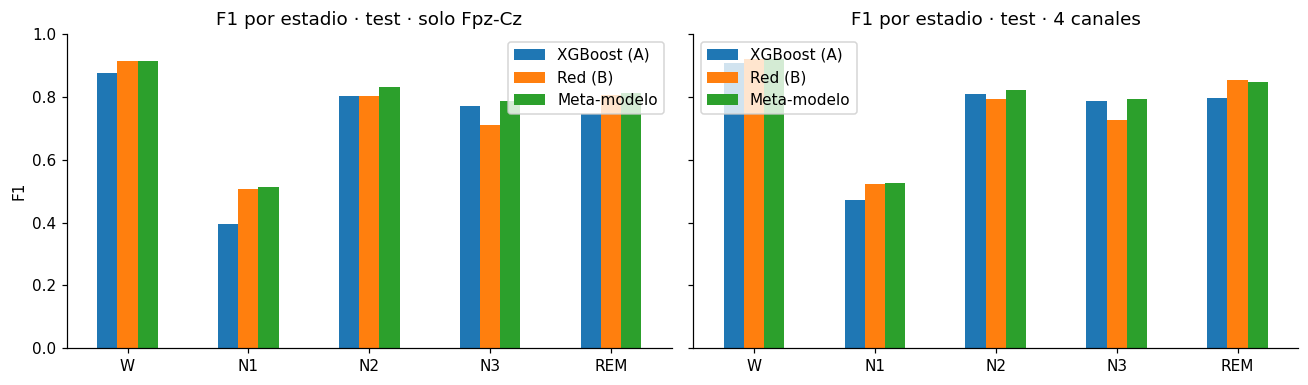

In [22]:
# F1 por estadio en el test: A, B y meta-modelo
fig, axes = plt.subplots(1, 2, figsize=(12, 3.6), sharey=True)
for ax, (c, nombre) in zip(axes, [("fpz", "solo Fpz-Cz"), ("eeg2_eog_emg", "4 canales")]):
    f1 = pd.DataFrame({name: [metrics_of(MODELOS[name][c]["test"])[f"f1_{s}"] for s in ESTADIOS]
                       for name in ("XGBoost (A)", "Red (B)", "Meta-modelo")}, index=ESTADIOS)
    f1.plot.bar(ax=ax, rot=0)
    ax.set_title(f"F1 por estadio · test · {nombre}")
    ax.set_ylim(0, 1)
axes[0].set_ylabel("F1")
plt.tight_layout()
plt.show()

### Matrices de confusión

Test, solo con Fpz-Cz y con los 4 canales. Cada fila es el estadio real y suma 100 %.

In [23]:
# Función para graficar una matriz de confusión
def plot_confusion(cm, title, ax):
    cm = np.asarray(cm)
    cmn = cm / cm.sum(1, keepdims=True)
    ax.imshow(cmn, cmap="Blues", vmin=0, vmax=1)
    for i in range(K):
        for j in range(K):
            ax.text(j, i, f"{cmn[i, j]:.0%}\n{cm[i, j]:,}", ha="center", va="center", fontsize=8,
                    color="white" if cmn[i, j] > 0.6 else "black")
    ax.set_xticks(range(K), ESTADIOS)
    ax.set_yticks(range(K), ESTADIOS)
    ax.set_xlabel("predicho")
    ax.set_ylabel("real")
    ax.set_title(title, fontsize=10)

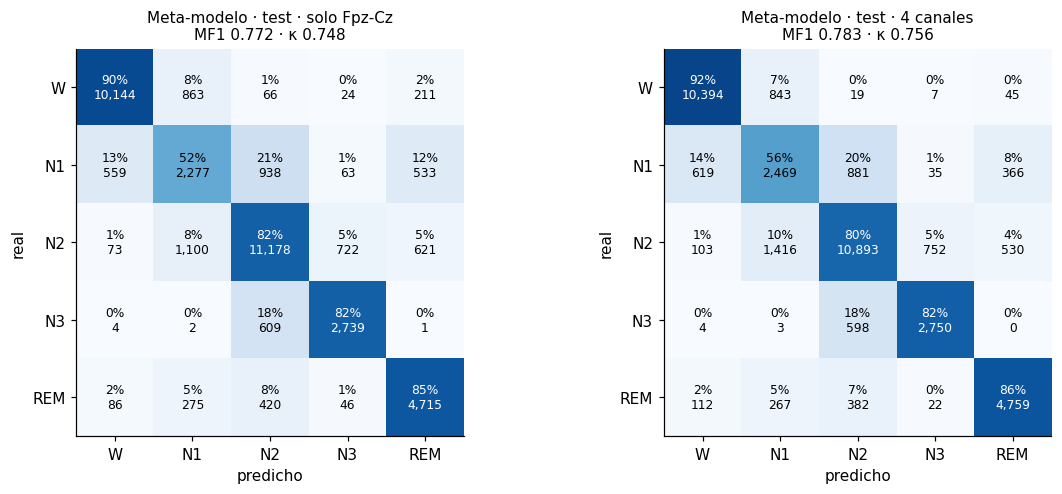

In [24]:
# Matrices de confusión del meta-modelo en el test
fig, axes = plt.subplots(1, 2, figsize=(11, 4.6))
for ax, c, nombre in zip(axes, ["fpz", "eeg2_eog_emg"], ["solo Fpz-Cz", "4 canales"]):
    m = metrics_of(META[c]["test"])
    plot_confusion(m["confusion"], f"Meta-modelo · test · {nombre}\nMF1 {m['mf1']:.3f} · κ {m['kappa']:.3f}", ax)
plt.tight_layout()
plt.show()

## 8. Usar el modelo guardado

Se cargan los archivos de `modelo/meta_modelo/`, se arman las 54 entradas de una noche de test con las predicciones de A y B (solo Fpz-Cz) y se comprueba que da lo mismo que el modelo recién entrenado.

In [25]:
# Cargar el meta-modelo guardado y predecir una noche de test con Fpz-Cz
meta_lr = joblib.load(MODELO / "meta_lr.joblib")
meta_xgb = xgb.XGBClassifier()
meta_xgb.load_model(MODELO / "meta_xgb.json")
columnas = json.loads((MODELO / "columnas.json").read_text())

noche = sorted(META_TEST["fpz"])[0]
y, pa = A["fpz"]["test"][noche]
pb = B["fpz"]["test"][noche][1]
X = entradas(pa, pb, mascara("fpz"))[columnas]
proba = np.mean([meta_lr.predict_proba(X), meta_xgb.predict_proba(X)], axis=0)
assert np.allclose(proba, META_TEST["fpz"][noche][1], atol=1e-6)

v = y >= 0
m = compute_metrics(y[v], proba.argmax(1)[v])
print(f"{noche}, solo Fpz-Cz: {len(y)} épocas · MF1 {m['mf1']:.3f} · κ {m['kappa']:.3f}")

SC4001, solo Fpz-Cz: 841 épocas · MF1 0.887 · κ 0.894


Épocas de esa noche en que A y B no están de acuerdo: qué dijo cada uno y qué decidió el meta-modelo.

In [26]:
# Épocas en que A y B no coinciden
desacuerdo = np.where(v & (pa.argmax(1) != pb.argmax(1)))[0][:10]
pd.DataFrame({"época": desacuerdo,
              "real": [ESTADIOS[y[i]] for i in desacuerdo],
              "A": [ESTADIOS[pa[i].argmax()] for i in desacuerdo],
              "B": [ESTADIOS[pb[i].argmax()] for i in desacuerdo],
              "meta-modelo": [ESTADIOS[proba[i].argmax()] for i in desacuerdo],
              "confianza": proba[desacuerdo].max(1).round(2)}).set_index("época")

,real,A,B,meta-modelo,confianza
época,,,,,
59,W,W,N1,N1,0.52
99,W,N2,N1,N1,0.52
100,N3,N2,N3,N3,0.48
101,N3,N2,N3,N3,0.54
103,N2,N2,N3,N3,0.56
104,N3,N2,N3,N3,0.62
115,N2,N2,N3,N3,0.57
116,N2,N2,N3,N2,0.67
124,N3,N2,N3,N2,0.65


## 9. Conclusiones

- A (100 columnas) y B comparten entre el 56 % y el 62 % de sus errores, bajo la regla del 70 %, así que tiene sentido combinarlos.
- El meta-modelo es el mejor en las 12 combinaciones. En el test supera de forma significativa a A en las 12 y a B en 7.
- Frente a la votación simple, la ganancia es pequeña (+0.004 a +0.008) y solo es significativa con Fpz-Cz + EOG: casi toda la mejora viene de juntar dos formas distintas de ver la noche.
- Con solo Fpz-Cz cumple la meta del proyecto (MF1 0.772, κ 0.748). Con solo Pz-Oz no llega en MF1 (0.735).
- Con A de 100 columnas, el sistema queda casi igual que con el de 719: en el test, 0.772 frente a 0.773 con Fpz-Cz y 0.783 frente a 0.784 con los 4 canales. Lo que A pierde, el meta-modelo lo compensa con B.